In [2]:
!pip install pandas openpyxl matplotlib sentence-transformers vendi-score scikit-learn krippendorff tf-keras -q

In [3]:
!pip install scikit-learn krippendorff matplotlib -q

In [4]:
import krippendorff
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
from itertools import combinations
from sklearn.metrics import cohen_kappa_score
from pathlib import Path
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter
from itertools import combinations
import krippendorff
from sklearn.metrics import cohen_kappa_score


In [ ]:
# ============================================================
# Remap full labels -> L1-L7 and save a new CSV
# ============================================================

input_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G.csv"
)
output_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7.csv"
)

df = pd.read_csv(input_file)

label_mapping = {
    "1-No Concern": "L1",
    "2- Distressed Self-Disclosure": "L2",
    "3-Self-Identified Crisis Symptoms and Seeking Support": "L3",
    "4- Self-Identified Crisis Symptoms but Not Seeking Support": "L4",
    "5- Acute Crisis with Suicidal Ideation": "L5",
    "6- Not Relevant to the Research": "L6",
    "Other": "L7",
}

# Columns that hold a single label value
label_cols = [
    "reviewer1",
    "reviewer2",
    "reviewer3",
    "reviewer4",
    "reviewer5",
    "reviewer6",
    "reviewer7",
    "reviewer8",
    "ground_truth_label",
    "Llama3.1-8B",
    "Hermes3-8B",
    "Qwen2.5-7B",
    "GPT-5.4-mini",
    "GPT-5.6-Terra",
    "Claude-Opus-5",
]

df_mapped = df.copy()

for col in label_cols:
    df_mapped[col] = (
        df_mapped[col]
        .astype("string")
        .str.strip()
        .map(label_mapping)
    )


def remap_tie_labels(value):
    """Replace full label names inside compound tie strings, e.g.
    '1-No Concern (3 votes) | 2- Distressed Self-Disclosure (3 votes)'
    -> 'L1 (3 votes) | L2 (3 votes)'
    """
    if pd.isna(value) or str(value).strip() == "":
        return value
    text = str(value)
    # Longest keys first so partial overlaps do not break replacement
    for full_label, short_label in sorted(
        label_mapping.items(), key=lambda x: len(x[0]), reverse=True
    ):
        text = text.replace(full_label, short_label)
    return text


if "tie_labels" in df_mapped.columns:
    df_mapped["tie_labels"] = df_mapped["tie_labels"].apply(remap_tie_labels)

df_mapped.to_csv(output_file, index=False)

print(f"Saved: {output_file.resolve()}")
print(f"Rows: {len(df_mapped)}")
print("\nLabel mapping:")
for k, v in label_mapping.items():
    print(f"  {k} -> {v}")

print("\nSample ground_truth_label / LLM columns:")
sample_cols = ["ground_truth_label", "Llama3.1-8B", "Claude-Opus-5", "tie_labels"]
display(df_mapped[sample_cols].head(10))

print("\nUnique values after mapping:")
for col in label_cols:
    print(f"  {col}: {sorted(df_mapped[col].dropna().unique().tolist())}")


In [5]:
# ============================================================
# Consolidate reviewer L1/L6/L7 -> L1 (reviewers only; LLMs unchanged)
# ============================================================

l17_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7.csv"
)
consolidated_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7_reviewers_L1L6L7_as_L1.csv"
)

df_consol = pd.read_csv(l17_file)

reviewer_cols = [
    "reviewer1",
    "reviewer2",
    "reviewer3",
    "reviewer4",
    "reviewer5",
    "reviewer6",
    "reviewer7",
    "reviewer8",
]

# Merge L6 and L7 into L1 for human reviewers only
consolidate_to_l1 = {"L6": "L1", "L7": "L1"}

for col in reviewer_cols:
    before = df_consol[col].value_counts(dropna=False)
    df_consol[col] = (
        df_consol[col]
        .astype("string")
        .str.strip()
        .replace(consolidate_to_l1)
    )
    after = df_consol[col].value_counts(dropna=False)
    print(f"{col}: L6/L7 -> L1")
    print(f"  before: {before.to_dict()}")
    print(f"  after:  {after.to_dict()}\n")

df_consol.to_csv(consolidated_file, index=False)

print(f"Saved: {consolidated_file.resolve()}")
print("\nReviewer unique labels (should be L1-L5 only):")
for col in reviewer_cols:
    print(f"  {col}: {sorted(df_consol[col].dropna().unique().tolist())}")

print("\nLLM labels left unchanged (sample):")
llm_cols = [
    "Llama3.1-8B",
    "Hermes3-8B",
    "Qwen2.5-7B",
    "GPT-5.4-mini",
    "GPT-5.6-Terra",
    "Claude-Opus-5",
]
for col in llm_cols:
    print(f"  {col}: {sorted(df_consol[col].dropna().unique().tolist())}")

display(df_consol[reviewer_cols + ["ground_truth_label", "Llama3.1-8B"]].head(10))


reviewer1: L6/L7 -> L1
  before: {'L1': 116, 'L7': 13, 'L2': 10, 'L3': 7, 'L4': 2, 'L6': 1}
  after:  {'L1': 130, 'L2': 10, 'L3': 7, 'L4': 2}

reviewer2: L6/L7 -> L1
  before: {'L1': 82, 'L2': 29, 'L3': 17, 'L6': 11, 'L7': 9, 'L4': 1}
  after:  {'L1': 102, 'L2': 29, 'L3': 17, 'L4': 1}

reviewer3: L6/L7 -> L1
  before: {'L1': 53, 'L7': 35, 'L2': 26, 'L3': 23, 'L6': 6, 'L4': 4, 'L5': 2}
  after:  {'L1': 94, 'L2': 26, 'L3': 23, 'L4': 4, 'L5': 2}

reviewer4: L6/L7 -> L1
  before: {'L1': 72, 'L7': 40, 'L2': 19, 'L4': 9, 'L6': 7, 'L3': 2}
  after:  {'L1': 119, 'L2': 19, 'L4': 9, 'L3': 2}

reviewer5: L6/L7 -> L1
  before: {'L1': 99, 'L2': 18, 'L6': 14, 'L3': 13, 'L5': 5}
  after:  {'L1': 113, 'L2': 18, 'L3': 13, 'L5': 5}

reviewer6: L6/L7 -> L1
  before: {'L1': 65, 'L6': 36, 'L3': 17, 'L2': 16, 'L5': 10, 'L4': 5}
  after:  {'L1': 101, 'L3': 17, 'L2': 16, 'L5': 10, 'L4': 5}

reviewer7: L6/L7 -> L1
  before: {'L2': 43, 'L1': 42, 'L6': 33, 'L3': 21, 'L5': 6, 'L4': 4}
  after:  {'L1': 75, 'L2': 4

,reviewer1,reviewer2,reviewer3,reviewer4,reviewer5,reviewer6,reviewer7,reviewer8,ground_truth_label,Llama3.1-8B
0,L1,L1,L1,L1,L2,L1,L1,L1,L1,L6
1,L1,L1,L1,L1,L1,L1,L1,L2,L1,L6
2,L2,L1,L1,L1,L3,L2,L1,L1,L1,L6
3,L2,L1,L1,L4,L2,L1,L2,L1,L2,L2
4,L1,L2,L1,L1,L1,L2,L3,L2,L2,L2
5,L1,L2,L2,L1,L5,L5,L4,L3,L5,L4
6,L1,L2,L2,L1,L2,L2,L3,L2,L2,L6
7,L1,L2,L2,L1,L5,L5,L4,L3,L5,L4
8,L1,L2,L2,L2,L5,L3,L3,L5,L2,L3
9,L1,L1,L2,L1,L5,L3,L5,L5,L5,L5


In [ ]:
# ============================================================
# Consolidate L6 and L7 -> L6 (from L1-L7 file)
# ============================================================

l17_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7.csv"
)
output_l6_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L6_L7_as_L6.csv"
)

df_l6 = pd.read_csv(l17_file)

label_cols = [
    "reviewer1",
    "reviewer2",
    "reviewer3",
    "reviewer4",
    "reviewer5",
    "reviewer6",
    "reviewer7",
    "reviewer8",
    "ground_truth_label",
    "Llama3.1-8B",
    "Hermes3-8B",
    "Qwen2.5-7B",
    "GPT-5.4-mini",
    "GPT-5.6-Terra",
    "Claude-Opus-5",
]

# Merge L7 into L6; L6 stays L6
consolidate_l6 = {"L7": "L6"}

for col in label_cols:
    before_l7 = (df_l6[col].astype("string").str.strip() == "L7").sum()
    df_l6[col] = (
        df_l6[col]
        .astype("string")
        .str.strip()
        .replace(consolidate_l6)
    )
    if before_l7:
        print(f"{col}: remapped {before_l7} L7 -> L6")


def remap_tie_l7_to_l6(value):
    if pd.isna(value) or str(value).strip() == "":
        return value
    return str(value).replace("L7", "L6")


if "tie_labels" in df_l6.columns:
    df_l6["tie_labels"] = df_l6["tie_labels"].apply(remap_tie_l7_to_l6)

df_l6.to_csv(output_l6_file, index=False)

print(f"\nSaved: {output_l6_file.resolve()}")
print(f"Rows: {len(df_l6)}")

print("\nUnique labels after L7 -> L6:")
for col in label_cols:
    print(f"  {col}: {sorted(df_l6[col].dropna().unique().tolist())}")

display(
    df_l6[
        ["reviewer1", "reviewer3", "reviewer4", "reviewer8", "ground_truth_label"]
    ].head(10)
)


In [6]:
# ============================================================
# Inter-rater reliability: reviewers 1-8
# (L1/L6/L7 consolidated to L1)
# ============================================================

from vendi_score import vendi

irr_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7_reviewers_L1L6L7_as_L1.csv"
)

df_irr = pd.read_csv(irr_file)

REVIEWER_COLS = [f"reviewer{i}" for i in range(1, 9)]
ratings = df_irr[REVIEWER_COLS].copy()

# Clean whitespace / empty strings
ratings = ratings.replace(r"^\s*$", np.nan, regex=True)
ratings = ratings.apply(
    lambda col: col.map(lambda x: x.strip() if isinstance(x, str) else x)
)

total_tweets = len(ratings)
n_reviewers = len(REVIEWER_COLS)

print("Label distribution (reviewers 1-8):")
print(ratings.stack().value_counts().sort_index())

# ------------------------------------------------------------
# Ordinal map (L1-L5 severity order after consolidation)
# ------------------------------------------------------------
ORDINAL_MAP = {
    "L1": 1,
    "L2": 2,
    "L3": 3,
    "L4": 4,
    "L5": 5,
}


# ------------------------------------------------------------
# Per-tweet agreement rate (max vote share)
# ------------------------------------------------------------
def agreement_rate(row: pd.Series) -> float:
    labels = row.dropna().tolist()
    if not labels:
        return np.nan
    return max(Counter(labels).values()) / len(labels)


tweet_agreement = ratings.apply(agreement_rate, axis=1)

majority_count = int((tweet_agreement > 0.50).sum())
majority_pct = majority_count / total_tweets * 100

full_count = int((tweet_agreement == 1.0).sum())
full_pct = full_count / total_tweets * 100


# ------------------------------------------------------------
# Fleiss' kappa (complete cases only)
# ------------------------------------------------------------
def fleiss_kappa(rating_matrix: pd.DataFrame) -> float:
    labels = sorted(rating_matrix.stack().unique())
    label_to_idx = {label: i for i, label in enumerate(labels)}
    n_subjects = len(rating_matrix)
    n_raters = rating_matrix.shape[1]
    counts = np.zeros((n_subjects, len(labels)), dtype=int)

    for i, row in enumerate(rating_matrix.values):
        for label in row:
            counts[i, label_to_idx[label]] += 1

    p_i = (counts * (counts - 1)).sum(axis=1) / (n_raters * (n_raters - 1))
    p_bar = p_i.mean()
    p_j = counts.sum(axis=0) / (n_subjects * n_raters)
    p_e = (p_j**2).sum()
    if p_e == 1:
        return np.nan
    return (p_bar - p_e) / (1 - p_e)


complete_ratings = ratings.dropna(how="any").copy()
fleiss_value = fleiss_kappa(complete_ratings)


# ------------------------------------------------------------
# Krippendorff's alpha — nominal
# ------------------------------------------------------------
nominal_labels = sorted(ratings.stack().dropna().unique())
nominal_codes = {label: i for i, label in enumerate(nominal_labels)}
nominal_ratings = ratings.replace(nominal_codes).astype(float)

alpha_nominal = krippendorff.alpha(
    reliability_data=nominal_ratings.T.to_numpy(dtype=float),
    level_of_measurement="nominal",
)

# ------------------------------------------------------------
# Krippendorff's alpha — ordinal (L1-L5)
# ------------------------------------------------------------
ordinal_ratings = ratings.replace(ORDINAL_MAP)
ordinal_ratings = ordinal_ratings.apply(pd.to_numeric, errors="coerce").astype(float)

alpha_ordinal = krippendorff.alpha(
    reliability_data=ordinal_ratings.T.to_numpy(dtype=float),
    level_of_measurement="ordinal",
)


# ------------------------------------------------------------
# Normalized Reviewer Vendi Score
# ------------------------------------------------------------
S_reviewers = np.zeros((n_reviewers, n_reviewers))
for i in range(n_reviewers):
    for j in range(n_reviewers):
        a = ratings.iloc[:, i]
        b = ratings.iloc[:, j]
        valid = a.notna() & b.notna()
        if valid.sum() == 0:
            sim = 0.0
        else:
            sim = float(np.mean(a.loc[valid].values == b.loc[valid].values))
        S_reviewers[i, j] = sim

reviewer_vendi = vendi.score_K(S_reviewers)
reviewer_vendi_normalized = reviewer_vendi / n_reviewers


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------
irr_summary = pd.Series(
    {
        "Number of tweets": total_tweets,
        "Number of reviewers": n_reviewers,
        "Majority agreement (>50%) count": majority_count,
        "Majority agreement (>50%) %": majority_pct,
        "Full agreement (100%) count": full_count,
        "Full agreement (100%) %": full_pct,
        "Fleiss' kappa (nominal)": fleiss_value,
        "Krippendorff's alpha (nominal)": alpha_nominal,
        "Krippendorff's alpha (ordinal)": alpha_ordinal,
        "Reviewer Vendi Score": reviewer_vendi,
        "Normalized Reviewer Vendi Score": reviewer_vendi_normalized,
    }
)

print("\n==========================================")
print("INTER-RATER RELIABILITY (Reviewers 1-8)")
print("File:", irr_file.name)
print("==========================================")
print(irr_summary.to_frame("Value").round(4))

print("\n==========================================")
print("KEY METRICS")
print("==========================================")
print(f"Majority agreement (>50%): {majority_count} ({majority_pct:.2f}%)")
print(f"Full agreement (100%):     {full_count} ({full_pct:.2f}%)")
print(f"Fleiss' κ:                 {fleiss_value:.4f}")
print(f"Krippendorff's α (nominal):{alpha_nominal:.4f}")
print(f"Krippendorff's α (ordinal):{alpha_ordinal:.4f}")
print(
    f"Normalized Reviewer Vendi: {reviewer_vendi_normalized:.4f} "
    f"({reviewer_vendi_normalized * 100:.2f}%)"
)


Label distribution (reviewers 1-8):
L1    840
L2    174
L3    125
L4     25
L5     28
Name: count, dtype: int64

INTER-RATER RELIABILITY (Reviewers 1-8)
File: Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7_reviewers_L1L6L7_as_L1.csv
                                    Value
Number of tweets                 149.0000
Number of reviewers                8.0000
Majority agreement (>50%) count  121.0000
Majority agreement (>50%) %       81.2081
Full agreement (100%) count       49.0000
Full agreement (100%) %           32.8859
Fleiss' kappa (nominal)            0.2913
Krippendorff's alpha (nominal)     0.2919
Krippendorff's alpha (ordinal)     0.4467
Reviewer Vendi Score               3.1387
Normalized Reviewer Vendi Score    0.3923

KEY METRICS
Majority agreement (>50%): 121 (81.21%)
Full agreement (100%):     49 (32.89%)
Fleiss' κ:                 0.2913
Krippendorff's α (nominal):0.2919
Krippendorff's α (ordinal):0.4467
Normalized Reviewer Vendi: 0.3923 (

In [7]:
# ============================================================
# Inter-rater reliability: reviewers 1-8
# Labels L1-L6 (L7 consolidated into L6)
# ============================================================

from vendi_score import vendi

irr_l6_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L6_L7_as_L6.csv"
)

df_irr_l6 = pd.read_csv(irr_l6_file)

REVIEWER_COLS = [f"reviewer{i}" for i in range(1, 9)]
ratings = df_irr_l6[REVIEWER_COLS].copy()

ratings = ratings.replace(r"^\s*$", np.nan, regex=True)
ratings = ratings.apply(
    lambda col: col.map(lambda x: x.strip() if isinstance(x, str) else x)
)

total_tweets = len(ratings)
n_reviewers = len(REVIEWER_COLS)

print("Label distribution (reviewers 1-8, L1-L6):")
print(ratings.stack().value_counts().sort_index())

# Ordinal severity scale is L1-L5 only.
# L6 (Not Relevant / Other) is excluded from ordinal alpha.
ORDINAL_MAP = {
    "L1": 1,
    "L2": 2,
    "L3": 3,
    "L4": 4,
    "L5": 5,
}


def agreement_rate(row: pd.Series) -> float:
    labels = row.dropna().tolist()
    if not labels:
        return np.nan
    return max(Counter(labels).values()) / len(labels)


tweet_agreement = ratings.apply(agreement_rate, axis=1)

majority_count = int((tweet_agreement > 0.50).sum())
majority_pct = majority_count / total_tweets * 100

full_count = int((tweet_agreement == 1.0).sum())
full_pct = full_count / total_tweets * 100


def fleiss_kappa(rating_matrix: pd.DataFrame) -> float:
    labels = sorted(rating_matrix.stack().unique())
    label_to_idx = {label: i for i, label in enumerate(labels)}
    n_subjects = len(rating_matrix)
    n_raters = rating_matrix.shape[1]
    counts = np.zeros((n_subjects, len(labels)), dtype=int)

    for i, row in enumerate(rating_matrix.values):
        for label in row:
            counts[i, label_to_idx[label]] += 1

    p_i = (counts * (counts - 1)).sum(axis=1) / (n_raters * (n_raters - 1))
    p_bar = p_i.mean()
    p_j = counts.sum(axis=0) / (n_subjects * n_raters)
    p_e = (p_j**2).sum()
    if p_e == 1:
        return np.nan
    return (p_bar - p_e) / (1 - p_e)


complete_ratings = ratings.dropna(how="any").copy()
fleiss_value = fleiss_kappa(complete_ratings)

# Krippendorff nominal (all L1-L6)
nominal_labels = sorted(ratings.stack().dropna().unique())
nominal_codes = {label: i for i, label in enumerate(nominal_labels)}
nominal_ratings = ratings.replace(nominal_codes).astype(float)

alpha_nominal = krippendorff.alpha(
    reliability_data=nominal_ratings.T.to_numpy(dtype=float),
    level_of_measurement="nominal",
)

# Krippendorff ordinal (L1-L5; L6 -> NaN)
ordinal_ratings = ratings.replace(ORDINAL_MAP)
ordinal_ratings = ordinal_ratings.apply(pd.to_numeric, errors="coerce").astype(float)

alpha_ordinal = krippendorff.alpha(
    reliability_data=ordinal_ratings.T.to_numpy(dtype=float),
    level_of_measurement="ordinal",
)

# Normalized Reviewer Vendi Score
S_reviewers = np.zeros((n_reviewers, n_reviewers))
for i in range(n_reviewers):
    for j in range(n_reviewers):
        a = ratings.iloc[:, i]
        b = ratings.iloc[:, j]
        valid = a.notna() & b.notna()
        if valid.sum() == 0:
            sim = 0.0
        else:
            sim = float(np.mean(a.loc[valid].values == b.loc[valid].values))
        S_reviewers[i, j] = sim

reviewer_vendi = vendi.score_K(S_reviewers)
reviewer_vendi_normalized = reviewer_vendi / n_reviewers

irr_summary_l6 = pd.Series(
    {
        "Number of tweets": total_tweets,
        "Number of reviewers": n_reviewers,
        "Majority agreement (>50%) count": majority_count,
        "Majority agreement (>50%) %": majority_pct,
        "Full agreement (100%) count": full_count,
        "Full agreement (100%) %": full_pct,
        "Fleiss' kappa (nominal)": fleiss_value,
        "Krippendorff's alpha (nominal)": alpha_nominal,
        "Krippendorff's alpha (ordinal, excl. L6)": alpha_ordinal,
        "Reviewer Vendi Score": reviewer_vendi,
        "Normalized Reviewer Vendi Score": reviewer_vendi_normalized,
    }
)

print("\n==========================================")
print("INTER-RATER RELIABILITY (Reviewers 1-8, L1-L6)")
print("File:", irr_l6_file.name)
print("==========================================")
print(irr_summary_l6.to_frame("Value").round(4))

print("\n==========================================")
print("KEY METRICS")
print("==========================================")
print(f"Majority agreement (>50%): {majority_count} ({majority_pct:.2f}%)")
print(f"Full agreement (100%):     {full_count} ({full_pct:.2f}%)")
print(f"Fleiss' κ:                 {fleiss_value:.4f}")
print(f"Krippendorff's α (nominal):{alpha_nominal:.4f}")
print(f"Krippendorff's α (ordinal):{alpha_ordinal:.4f}")
print(
    f"Normalized Reviewer Vendi: {reviewer_vendi_normalized:.4f} "
    f"({reviewer_vendi_normalized * 100:.2f}%)"
)


Label distribution (reviewers 1-8, L1-L6):
L1    579
L2    174
L3    125
L4     25
L5     28
L6    261
Name: count, dtype: int64

INTER-RATER RELIABILITY (Reviewers 1-8, L1-L6)
File: Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L6_L7_as_L6.csv
                                             Value
Number of tweets                          149.0000
Number of reviewers                         8.0000
Majority agreement (>50%) count            92.0000
Majority agreement (>50%) %                61.7450
Full agreement (100%) count                 0.0000
Full agreement (100%) %                     0.0000
Fleiss' kappa (nominal)                     0.1442
Krippendorff's alpha (nominal)              0.1449
Krippendorff's alpha (ordinal, excl. L6)    0.4941
Reviewer Vendi Score                        5.1957
Normalized Reviewer Vendi Score             0.6495

KEY METRICS
Majority agreement (>50%): 92 (61.74%)
Full agreement (100%):     0 (0.00%)
Fleiss' κ:            

In [8]:
# ============================================================
# Inter-rater reliability among LLMs (labels L1-L7)
# ============================================================

from vendi_score import vendi

llm_irr_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7.csv"
)

df_llm = pd.read_csv(llm_irr_file)

LLM_COLS = [
    "Llama3.1-8B",
    "Hermes3-8B",
    "Qwen2.5-7B",
    "GPT-5.4-mini",
    "GPT-5.6-Terra",
    "Claude-Opus-5",
]

ratings = df_llm[LLM_COLS].copy()
ratings = ratings.replace(r"^\s*$", np.nan, regex=True)
ratings = ratings.apply(
    lambda col: col.map(lambda x: x.strip() if isinstance(x, str) else x)
)

total_tweets = len(ratings)
n_llms = len(LLM_COLS)

print("Missing LLM annotations:")
for llm in LLM_COLS:
    missing = ratings[llm].isna().sum()
    print(f"  {llm}: {ratings[llm].notna().sum()} available, {missing} missing")

print("\nLabel distribution (all LLMs, L1-L7 space):")
print(ratings.stack().value_counts().reindex(
    [f"L{i}" for i in range(1, 8)], fill_value=0
))

# Ordinal severity: L1-L5 only.
# L6 (Not Relevant) and L7 (Other) are excluded from ordinal alpha.
ORDINAL_MAP = {
    "L1": 1,
    "L2": 2,
    "L3": 3,
    "L4": 4,
    "L5": 5,
}


def agreement_rate(row: pd.Series) -> float:
    labels = row.dropna().tolist()
    if not labels:
        return np.nan
    return max(Counter(labels).values()) / len(labels)


tweet_agreement = ratings.apply(agreement_rate, axis=1)

majority_count = int((tweet_agreement > 0.50).sum())
majority_pct = majority_count / total_tweets * 100

full_count = int((tweet_agreement == 1.0).sum())
full_pct = full_count / total_tweets * 100


def fleiss_kappa(rating_matrix: pd.DataFrame) -> float:
    labels = sorted(rating_matrix.stack().unique())
    label_to_idx = {label: i for i, label in enumerate(labels)}
    n_subjects = len(rating_matrix)
    n_raters = rating_matrix.shape[1]
    counts = np.zeros((n_subjects, len(labels)), dtype=int)

    for i, row in enumerate(rating_matrix.values):
        for label in row:
            counts[i, label_to_idx[label]] += 1

    p_i = (counts * (counts - 1)).sum(axis=1) / (n_raters * (n_raters - 1))
    p_bar = p_i.mean()
    p_j = counts.sum(axis=0) / (n_subjects * n_raters)
    p_e = (p_j**2).sum()
    if p_e == 1:
        return np.nan
    return (p_bar - p_e) / (1 - p_e)


complete_ratings = ratings.dropna(how="any").copy()
fleiss_value = fleiss_kappa(complete_ratings)

# Nominal: all observed labels in L1-L7 space
nominal_labels = sorted(ratings.stack().dropna().unique())
nominal_codes = {label: i for i, label in enumerate(nominal_labels)}
nominal_ratings = ratings.replace(nominal_codes).astype(float)

alpha_nominal = krippendorff.alpha(
    reliability_data=nominal_ratings.T.to_numpy(dtype=float),
    level_of_measurement="nominal",
)

# Ordinal: L1-L5; L6/L7 -> NaN
ordinal_ratings = ratings.replace(ORDINAL_MAP)
ordinal_ratings = ordinal_ratings.apply(pd.to_numeric, errors="coerce").astype(float)

alpha_ordinal = krippendorff.alpha(
    reliability_data=ordinal_ratings.T.to_numpy(dtype=float),
    level_of_measurement="ordinal",
)

# Normalized LLM Vendi Score
S_llms = np.zeros((n_llms, n_llms))
for i in range(n_llms):
    for j in range(n_llms):
        a = ratings.iloc[:, i]
        b = ratings.iloc[:, j]
        valid = a.notna() & b.notna()
        if valid.sum() == 0:
            sim = 0.0
        else:
            sim = float(np.mean(a.loc[valid].values == b.loc[valid].values))
        S_llms[i, j] = sim

llm_vendi = vendi.score_K(S_llms)
llm_vendi_normalized = llm_vendi / n_llms

irr_summary_llm = pd.Series(
    {
        "Number of tweets": total_tweets,
        "Number of LLMs": n_llms,
        "Complete tweets for Fleiss' kappa": len(complete_ratings),
        "Majority agreement (>50%) count": majority_count,
        "Majority agreement (>50%) %": majority_pct,
        "Full agreement (100%) count": full_count,
        "Full agreement (100%) %": full_pct,
        "Fleiss' kappa (nominal)": fleiss_value,
        "Krippendorff's alpha (nominal)": alpha_nominal,
        "Krippendorff's alpha (ordinal, excl. L6/L7)": alpha_ordinal,
        "LLM Vendi Score": llm_vendi,
        "Normalized LLM Vendi Score": llm_vendi_normalized,
    }
)

print("\n==========================================")
print("INTER-RATER RELIABILITY (LLMs, L1-L7)")
print("File:", llm_irr_file.name)
print("LLMs:", ", ".join(LLM_COLS))
print("==========================================")
print(irr_summary_llm.to_frame("Value").round(4))

print("\n==========================================")
print("KEY METRICS")
print("==========================================")
print(f"Majority agreement (>50%): {majority_count} ({majority_pct:.2f}%)")
print(f"Full agreement (100%):     {full_count} ({full_pct:.2f}%)")
print(f"Fleiss' κ:                 {fleiss_value:.4f}  (n={len(complete_ratings)} complete)")
print(f"Krippendorff's α (nominal):{alpha_nominal:.4f}")
print(f"Krippendorff's α (ordinal):{alpha_ordinal:.4f}")
print(
    f"Normalized LLM Vendi:      {llm_vendi_normalized:.4f} "
    f"({llm_vendi_normalized * 100:.2f}%)"
)

print("\nLabel distribution by LLM:")
for llm in LLM_COLS:
    print(f"\n--- {llm} ---")
    print(ratings[llm].value_counts().reindex([f"L{i}" for i in range(1, 8)], fill_value=0))


Missing LLM annotations:
  Llama3.1-8B: 149 available, 0 missing
  Hermes3-8B: 148 available, 1 missing
  Qwen2.5-7B: 149 available, 0 missing
  GPT-5.4-mini: 149 available, 0 missing
  GPT-5.6-Terra: 149 available, 0 missing
  Claude-Opus-5: 149 available, 0 missing

Label distribution (all LLMs, L1-L7 space):
L1    536
L2     92
L3     58
L4     22
L5     33
L6    152
L7      0
Name: count, dtype: int64

INTER-RATER RELIABILITY (LLMs, L1-L7)
File: Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7.csv
LLMs: Llama3.1-8B, Hermes3-8B, Qwen2.5-7B, GPT-5.4-mini, GPT-5.6-Terra, Claude-Opus-5
                                                Value
Number of tweets                             149.0000
Number of LLMs                                 6.0000
Complete tweets for Fleiss' kappa            148.0000
Majority agreement (>50%) count              130.0000
Majority agreement (>50%) %                   87.2483
Full agreement (100%) count                   77.00

In [9]:
# ============================================================
# Consolidate LLM labels: L6 -> L1
# (no L7 among LLMs; reviewers left unchanged)
# Modifies:
# Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L6_L7_as_L6.csv
# ============================================================

llm_consol_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L6_L7_as_L6.csv"
)

df_llm_consol = pd.read_csv(llm_consol_file)

LLM_COLS = [
    "Llama3.1-8B",
    "Hermes3-8B",
    "Qwen2.5-7B",
    "GPT-5.4-mini",
    "GPT-5.6-Terra",
    "Claude-Opus-5",
]

print("Before (LLM L1 / L6 counts):")
for col in LLM_COLS:
    s = df_llm_consol[col].astype("string").str.strip()
    print(f"  {col}: L1={int((s == 'L1').sum())}, L6={int((s == 'L6').sum())}")

for col in LLM_COLS:
    df_llm_consol[col] = (
        df_llm_consol[col]
        .astype("string")
        .str.strip()
        .replace({"L6": "L1"})
    )

df_llm_consol.to_csv(llm_consol_file, index=False)

print("\nAfter (LLM unique labels):")
for col in LLM_COLS:
    print(f"  {col}: {sorted(df_llm_consol[col].dropna().unique().tolist())}")

print("\nReviewer labels unchanged (sample uniques):")
for col in [f"reviewer{i}" for i in range(1, 9)]:
    print(f"  {col}: {sorted(df_llm_consol[col].dropna().astype(str).str.strip().unique().tolist())}")

print(f"\nUpdated file: {llm_consol_file.resolve()}")
display(df_llm_consol[LLM_COLS].head(10))


Before (LLM L1 / L6 counts):
  Llama3.1-8B: L1=108, L6=0
  Hermes3-8B: L1=115, L6=0
  Qwen2.5-7B: L1=117, L6=0
  GPT-5.4-mini: L1=115, L6=0
  GPT-5.6-Terra: L1=117, L6=0
  Claude-Opus-5: L1=116, L6=0

After (LLM unique labels):
  Llama3.1-8B: ['L1', 'L2', 'L3', 'L4', 'L5']
  Hermes3-8B: ['L1', 'L2', 'L3', 'L4', 'L5']
  Qwen2.5-7B: ['L1', 'L2', 'L3', 'L5']
  GPT-5.4-mini: ['L1', 'L2', 'L3', 'L4', 'L5']
  GPT-5.6-Terra: ['L1', 'L2', 'L3', 'L4', 'L5']
  Claude-Opus-5: ['L1', 'L2', 'L3', 'L4', 'L5']

Reviewer labels unchanged (sample uniques):
  reviewer1: ['L1', 'L2', 'L3', 'L4', 'L6']
  reviewer2: ['L1', 'L2', 'L3', 'L4', 'L6']
  reviewer3: ['L1', 'L2', 'L3', 'L4', 'L5', 'L6']
  reviewer4: ['L1', 'L2', 'L3', 'L4', 'L6']
  reviewer5: ['L1', 'L2', 'L3', 'L5', 'L6']
  reviewer6: ['L1', 'L2', 'L3', 'L4', 'L5', 'L6']
  reviewer7: ['L1', 'L2', 'L3', 'L4', 'L5', 'L6']
  reviewer8: ['L1', 'L2', 'L3', 'L5', 'L6']

Updated file: C:\Users\kislam\Downloads\LLM-Data-Annotation\Veteran_Tweet_Label_PTS

,Llama3.1-8B,Hermes3-8B,Qwen2.5-7B,GPT-5.4-mini,GPT-5.6-Terra,Claude-Opus-5
0,L1,L1,L1,L1,L1,L1
1,L1,L1,L1,L1,L1,L1
2,L1,L1,L1,L1,L1,L1
3,L2,L2,L1,L2,L1,L1
4,L2,L1,L1,L1,L1,L1
5,L4,L4,L5,L4,L5,L5
6,L1,L1,L1,L1,L1,L1
7,L4,L4,L5,L4,L5,L5
8,L3,L4,L5,L5,L5,L5
9,L5,L5,L5,L5,L5,L5


In [10]:
# ============================================================
# Inter-rater reliability among LLMs
# Consolidated labels: L6 -> L1 (L1-L5)
# ============================================================

from vendi_score import vendi

llm_irr_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L6_L7_as_L6.csv"
)

df_llm = pd.read_csv(llm_irr_file)

LLM_COLS = [
    "Llama3.1-8B",
    "Hermes3-8B",
    "Qwen2.5-7B",
    "GPT-5.4-mini",
    "GPT-5.6-Terra",
    "Claude-Opus-5",
]

ratings = df_llm[LLM_COLS].copy()
ratings = ratings.replace(r"^\s*$", np.nan, regex=True)
ratings = ratings.apply(
    lambda col: col.map(lambda x: x.strip() if isinstance(x, str) else x)
)

total_tweets = len(ratings)
n_llms = len(LLM_COLS)

print("Missing LLM annotations:")
for llm in LLM_COLS:
    print(
        f"  {llm}: {ratings[llm].notna().sum()} available, "
        f"{ratings[llm].isna().sum()} missing"
    )

print("\nLabel distribution (LLMs, L6 consolidated into L1):")
print(ratings.stack().value_counts().reindex(
    [f"L{i}" for i in range(1, 6)], fill_value=0
))

ORDINAL_MAP = {"L1": 1, "L2": 2, "L3": 3, "L4": 4, "L5": 5}


def agreement_rate(row: pd.Series) -> float:
    labels = row.dropna().tolist()
    if not labels:
        return np.nan
    return max(Counter(labels).values()) / len(labels)


tweet_agreement = ratings.apply(agreement_rate, axis=1)

majority_count = int((tweet_agreement > 0.50).sum())
majority_pct = majority_count / total_tweets * 100
full_count = int((tweet_agreement == 1.0).sum())
full_pct = full_count / total_tweets * 100


def fleiss_kappa(rating_matrix: pd.DataFrame) -> float:
    labels = sorted(rating_matrix.stack().unique())
    label_to_idx = {label: i for i, label in enumerate(labels)}
    n_subjects = len(rating_matrix)
    n_raters = rating_matrix.shape[1]
    counts = np.zeros((n_subjects, len(labels)), dtype=int)
    for i, row in enumerate(rating_matrix.values):
        for label in row:
            counts[i, label_to_idx[label]] += 1
    p_i = (counts * (counts - 1)).sum(axis=1) / (n_raters * (n_raters - 1))
    p_bar = p_i.mean()
    p_j = counts.sum(axis=0) / (n_subjects * n_raters)
    p_e = (p_j**2).sum()
    if p_e == 1:
        return np.nan
    return (p_bar - p_e) / (1 - p_e)


complete_ratings = ratings.dropna(how="any").copy()
fleiss_value = fleiss_kappa(complete_ratings)

nominal_labels = sorted(ratings.stack().dropna().unique())
nominal_codes = {label: i for i, label in enumerate(nominal_labels)}
nominal_ratings = ratings.replace(nominal_codes).astype(float)
alpha_nominal = krippendorff.alpha(
    reliability_data=nominal_ratings.T.to_numpy(dtype=float),
    level_of_measurement="nominal",
)

ordinal_ratings = ratings.replace(ORDINAL_MAP)
ordinal_ratings = ordinal_ratings.apply(pd.to_numeric, errors="coerce").astype(float)
alpha_ordinal = krippendorff.alpha(
    reliability_data=ordinal_ratings.T.to_numpy(dtype=float),
    level_of_measurement="ordinal",
)

S_llms = np.zeros((n_llms, n_llms))
for i in range(n_llms):
    for j in range(n_llms):
        a = ratings.iloc[:, i]
        b = ratings.iloc[:, j]
        valid = a.notna() & b.notna()
        if valid.sum() == 0:
            sim = 0.0
        else:
            sim = float(np.mean(a.loc[valid].values == b.loc[valid].values))
        S_llms[i, j] = sim

llm_vendi = vendi.score_K(S_llms)
llm_vendi_normalized = llm_vendi / n_llms

irr_summary = pd.Series(
    {
        "Number of tweets": total_tweets,
        "Number of LLMs": n_llms,
        "Complete tweets for Fleiss' kappa": len(complete_ratings),
        "Majority agreement (>50%) count": majority_count,
        "Majority agreement (>50%) %": majority_pct,
        "Full agreement (100%) count": full_count,
        "Full agreement (100%) %": full_pct,
        "Fleiss' kappa (nominal)": fleiss_value,
        "Krippendorff's alpha (nominal)": alpha_nominal,
        "Krippendorff's alpha (ordinal)": alpha_ordinal,
        "LLM Vendi Score": llm_vendi,
        "Normalized LLM Vendi Score": llm_vendi_normalized,
    }
)

print("\n==========================================")
print("INTER-RATER RELIABILITY (LLMs, L6->L1)")
print("File:", llm_irr_file.name)
print("==========================================")
print(irr_summary.to_frame("Value").round(4))

print("\n==========================================")
print("KEY METRICS")
print("==========================================")
print(f"Majority agreement (>50%): {majority_count} ({majority_pct:.2f}%)")
print(f"Full agreement (100%):     {full_count} ({full_pct:.2f}%)")
print(f"Fleiss' κ:                 {fleiss_value:.4f}  (n={len(complete_ratings)} complete)")
print(f"Krippendorff's α (nominal):{alpha_nominal:.4f}")
print(f"Krippendorff's α (ordinal):{alpha_ordinal:.4f}")
print(
    f"Normalized LLM Vendi:      {llm_vendi_normalized:.4f} "
    f"({llm_vendi_normalized * 100:.2f}%)"
)


Missing LLM annotations:
  Llama3.1-8B: 149 available, 0 missing
  Hermes3-8B: 148 available, 1 missing
  Qwen2.5-7B: 149 available, 0 missing
  GPT-5.4-mini: 149 available, 0 missing
  GPT-5.6-Terra: 149 available, 0 missing
  Claude-Opus-5: 149 available, 0 missing

Label distribution (LLMs, L6 consolidated into L1):
L1    688
L2     92
L3     58
L4     22
L5     33
Name: count, dtype: int64

INTER-RATER RELIABILITY (LLMs, L6->L1)
File: Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L6_L7_as_L6.csv
                                      Value
Number of tweets                   149.0000
Number of LLMs                       6.0000
Complete tweets for Fleiss' kappa  148.0000
Majority agreement (>50%) count    137.0000
Majority agreement (>50%) %         91.9463
Full agreement (100%) count        110.0000
Full agreement (100%) %             73.8255
Fleiss' kappa (nominal)              0.6490
Krippendorff's alpha (nominal)       0.6498
Krippendorff's alpha (o

Label distribution across LLMs (L1-L7):
L1    536
L2     92
L3     58
L4     22
L5     33
L6    152
L7      0
Name: count, dtype: int64

PAIRWISE COHEN'S KAPPA (LLMs, L1-L7)
File: Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7.csv


,Llama3.1-8B,Hermes3-8B,Qwen2.5-7B,GPT-5.4-mini,GPT-5.6-Terra,Claude-Opus-5
Llama3.1-8B,1.0000,0.7295,0.6641,0.7218,0.6310,0.5001
Hermes3-8B,0.7295,1.0000,0.6132,0.6412,0.6059,0.4046
Qwen2.5-7B,0.6641,0.6132,1.0000,0.6584,0.6472,0.4332
GPT-5.4-mini,0.7218,0.6412,0.6584,1.0000,0.7760,0.5682
GPT-5.6-Terra,0.6310,0.6059,0.6472,0.7760,1.0000,0.6382
Claude-Opus-5,0.5001,0.4046,0.4332,0.5682,0.6382,1.0000



Mean: 0.6155 | Min: 0.4046 | Max: 0.7760


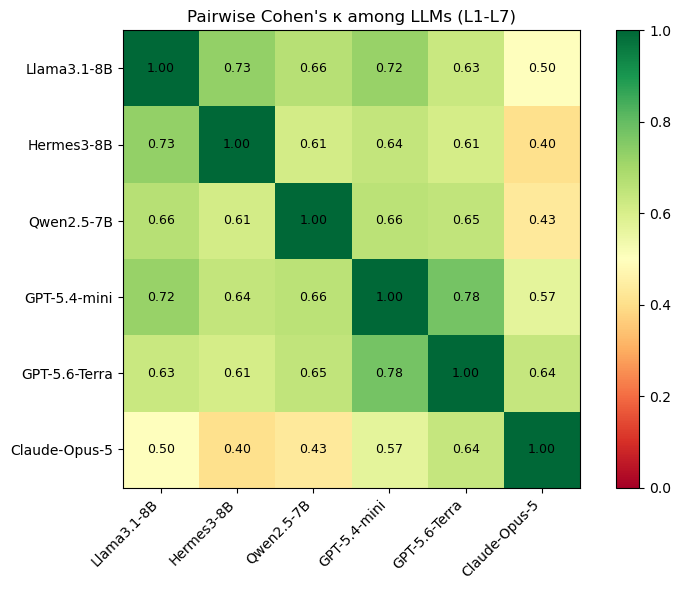

In [11]:
# ============================================================
# Pairwise Cohen's kappa among LLMs (labels L1-L7)
# ============================================================

from sklearn.metrics import cohen_kappa_score

pairwise_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7.csv"
)

df_pw = pd.read_csv(pairwise_file)

LLM_COLS = [
    "Llama3.1-8B",
    "Hermes3-8B",
    "Qwen2.5-7B",
    "GPT-5.4-mini",
    "GPT-5.6-Terra",
    "Claude-Opus-5",
]

ratings = df_pw[LLM_COLS].copy()
ratings = ratings.replace(r"^\s*$", np.nan, regex=True)
ratings = ratings.apply(
    lambda col: col.map(lambda x: x.strip() if isinstance(x, str) else x)
)

print("Label distribution across LLMs (L1-L7):")
print(
    ratings.stack()
    .value_counts()
    .reindex([f"L{i}" for i in range(1, 8)], fill_value=0)
)

pairwise_kappa = pd.DataFrame(
    index=LLM_COLS, columns=LLM_COLS, dtype=float
)

for a, b in combinations(LLM_COLS, 2):
    mask = ratings[a].notna() & ratings[b].notna()
    if mask.sum() == 0:
        kappa = np.nan
    else:
        kappa = cohen_kappa_score(
            ratings.loc[mask, a],
            ratings.loc[mask, b],
        )
    pairwise_kappa.loc[a, b] = kappa
    pairwise_kappa.loc[b, a] = kappa

for col in LLM_COLS:
    pairwise_kappa.loc[col, col] = 1.0

off_diag = ~np.eye(len(LLM_COLS), dtype=bool)
kappa_values = pairwise_kappa.where(off_diag).stack()

print("\n==========================================")
print("PAIRWISE COHEN'S KAPPA (LLMs, L1-L7)")
print("File:", pairwise_file.name)
print("==========================================")
display(pairwise_kappa.round(4))

print(
    f"\nMean: {kappa_values.mean():.4f} | "
    f"Min: {kappa_values.min():.4f} | "
    f"Max: {kappa_values.max():.4f}"
)

# Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(pairwise_kappa.astype(float), vmin=0, vmax=1, cmap="RdYlGn")
ax.set_xticks(range(len(LLM_COLS)), LLM_COLS, rotation=45, ha="right")
ax.set_yticks(range(len(LLM_COLS)), LLM_COLS)
ax.set_title("Pairwise Cohen's κ among LLMs (L1-L7)")

for i in range(len(LLM_COLS)):
    for j in range(len(LLM_COLS)):
        ax.text(
            j, i, f"{pairwise_kappa.iloc[i, j]:.2f}",
            ha="center", va="center", fontsize=9,
        )

fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()


In [12]:
# ============================================================
# IRR: Open-source LLMs vs Hosted LLMs (labels L1-L7)
# ============================================================

from vendi_score import vendi
from sklearn.metrics import cohen_kappa_score

irr_file = Path(
    "Veteran_Tweet_Label_PTSD_majority_vote_ground_truth_PLUS_LLM_Vote_Prompt_G_L1-L7.csv"
)

df_groups = pd.read_csv(irr_file)

OPEN_SOURCE_COLS = ["Llama3.1-8B", "Hermes3-8B", "Qwen2.5-7B"]
HOSTED_COLS = ["GPT-5.4-mini", "GPT-5.6-Terra", "Claude-Opus-5"]

ORDINAL_MAP = {"L1": 1, "L2": 2, "L3": 3, "L4": 4, "L5": 5}


def agreement_rate(row: pd.Series) -> float:
    labels = row.dropna().tolist()
    if not labels:
        return np.nan
    return max(Counter(labels).values()) / len(labels)


def fleiss_kappa(rating_matrix: pd.DataFrame) -> float:
    labels = sorted(rating_matrix.stack().unique())
    label_to_idx = {label: i for i, label in enumerate(labels)}
    n_subjects = len(rating_matrix)
    n_raters = rating_matrix.shape[1]
    counts = np.zeros((n_subjects, len(labels)), dtype=int)
    for i, row in enumerate(rating_matrix.values):
        for label in row:
            counts[i, label_to_idx[label]] += 1
    p_i = (counts * (counts - 1)).sum(axis=1) / (n_raters * (n_raters - 1))
    p_bar = p_i.mean()
    p_j = counts.sum(axis=0) / (n_subjects * n_raters)
    p_e = (p_j**2).sum()
    if p_e == 1:
        return np.nan
    return (p_bar - p_e) / (1 - p_e)


def compute_group_irr(df: pd.DataFrame, cols: list[str], group_name: str) -> pd.Series:
    ratings = df[cols].copy()
    ratings = ratings.replace(r"^\s*$", np.nan, regex=True)
    ratings = ratings.apply(
        lambda col: col.map(lambda x: x.strip() if isinstance(x, str) else x)
    )

    total_tweets = len(ratings)
    n_raters = len(cols)

    print(f"\n{'=' * 50}")
    print(f"{group_name}")
    print(f"Models: {', '.join(cols)}")
    print("=" * 50)

    print("Missing annotations:")
    for c in cols:
        print(f"  {c}: {ratings[c].notna().sum()} available, {ratings[c].isna().sum()} missing")

    print("\nLabel distribution:")
    print(
        ratings.stack()
        .value_counts()
        .reindex([f"L{i}" for i in range(1, 8)], fill_value=0)
    )

    tweet_agreement = ratings.apply(agreement_rate, axis=1)
    majority_count = int((tweet_agreement > 0.50).sum())
    majority_pct = majority_count / total_tweets * 100
    full_count = int((tweet_agreement == 1.0).sum())
    full_pct = full_count / total_tweets * 100

    complete_ratings = ratings.dropna(how="any").copy()
    fleiss_value = fleiss_kappa(complete_ratings)

    nominal_labels = sorted(ratings.stack().dropna().unique())
    nominal_codes = {label: i for i, label in enumerate(nominal_labels)}
    nominal_ratings = ratings.replace(nominal_codes).astype(float)
    alpha_nominal = krippendorff.alpha(
        reliability_data=nominal_ratings.T.to_numpy(dtype=float),
        level_of_measurement="nominal",
    )

    ordinal_ratings = ratings.replace(ORDINAL_MAP)
    ordinal_ratings = ordinal_ratings.apply(pd.to_numeric, errors="coerce").astype(float)
    alpha_ordinal = krippendorff.alpha(
        reliability_data=ordinal_ratings.T.to_numpy(dtype=float),
        level_of_measurement="ordinal",
    )

    S = np.zeros((n_raters, n_raters))
    for i in range(n_raters):
        for j in range(n_raters):
            a, b = ratings.iloc[:, i], ratings.iloc[:, j]
            valid = a.notna() & b.notna()
            S[i, j] = (
                0.0
                if valid.sum() == 0
                else float(np.mean(a.loc[valid].values == b.loc[valid].values))
            )
    vendi_raw = vendi.score_K(S)
    vendi_norm = vendi_raw / n_raters

    # Pairwise Cohen's kappa within group
    pairwise = pd.DataFrame(index=cols, columns=cols, dtype=float)
    for a, b in combinations(cols, 2):
        mask = ratings[a].notna() & ratings[b].notna()
        kappa = (
            np.nan
            if mask.sum() == 0
            else cohen_kappa_score(ratings.loc[mask, a], ratings.loc[mask, b])
        )
        pairwise.loc[a, b] = kappa
        pairwise.loc[b, a] = kappa
    for c in cols:
        pairwise.loc[c, c] = 1.0

    off = ~np.eye(n_raters, dtype=bool)
    kappa_vals = pairwise.where(off).stack()

    summary = pd.Series(
        {
            "Number of tweets": total_tweets,
            "Number of models": n_raters,
            "Complete tweets for Fleiss' kappa": len(complete_ratings),
            "Majority agreement (>50%) count": majority_count,
            "Majority agreement (>50%) %": majority_pct,
            "Full agreement (100%) count": full_count,
            "Full agreement (100%) %": full_pct,
            "Fleiss' kappa (nominal)": fleiss_value,
            "Krippendorff's alpha (nominal)": alpha_nominal,
            "Krippendorff's alpha (ordinal, excl. L6/L7)": alpha_ordinal,
            "Vendi Score": vendi_raw,
            "Normalized Vendi Score": vendi_norm,
            "Mean pairwise Cohen's kappa": kappa_vals.mean(),
            "Min pairwise Cohen's kappa": kappa_vals.min(),
            "Max pairwise Cohen's kappa": kappa_vals.max(),
        }
    )

    print("\nIRR summary:")
    print(summary.to_frame("Value").round(4))

    print("\nPairwise Cohen's κ:")
    display(pairwise.round(4))

    print("\nKEY METRICS")
    print(f"Majority agreement (>50%): {majority_count} ({majority_pct:.2f}%)")
    print(f"Full agreement (100%):     {full_count} ({full_pct:.2f}%)")
    print(f"Fleiss' κ:                 {fleiss_value:.4f}  (n={len(complete_ratings)})")
    print(f"Krippendorff's α (nominal):{alpha_nominal:.4f}")
    print(f"Krippendorff's α (ordinal):{alpha_ordinal:.4f}")
    print(f"Normalized Vendi:          {vendi_norm:.4f} ({vendi_norm * 100:.2f}%)")
    print(
        f"Pairwise Cohen's κ:        "
        f"mean={kappa_vals.mean():.4f}, min={kappa_vals.min():.4f}, max={kappa_vals.max():.4f}"
    )

    return summary


open_summary = compute_group_irr(df_groups, OPEN_SOURCE_COLS, "OPEN-SOURCE LLMs (L1-L7)")
hosted_summary = compute_group_irr(df_groups, HOSTED_COLS, "HOSTED LLMs (L1-L7)")

print("\n" + "=" * 50)
print("SIDE-BY-SIDE COMPARISON")
print("=" * 50)
comparison = pd.concat(
    [open_summary.rename("Open-source"), hosted_summary.rename("Hosted")],
    axis=1,
)
display(comparison.round(4))



OPEN-SOURCE LLMs (L1-L7)
Models: Llama3.1-8B, Hermes3-8B, Qwen2.5-7B
Missing annotations:
  Llama3.1-8B: 149 available, 0 missing
  Hermes3-8B: 148 available, 1 missing
  Qwen2.5-7B: 149 available, 0 missing

Label distribution:
L1    287
L2     56
L3     18
L4     15
L5     17
L6     53
L7      0
Name: count, dtype: int64

IRR summary:
                                                Value
Number of tweets                             149.0000
Number of models                               3.0000
Complete tweets for Fleiss' kappa            148.0000
Majority agreement (>50%) count              146.0000
Majority agreement (>50%) %                   97.9866
Full agreement (100%) count                  110.0000
Full agreement (100%) %                       73.8255
Fleiss' kappa (nominal)                        0.6676
Krippendorff's alpha (nominal)                 0.6716
Krippendorff's alpha (ordinal, excl. L6/L7)    0.8113
Vendi Score                                    1.5716
Normalized V

,Llama3.1-8B,Hermes3-8B,Qwen2.5-7B
Llama3.1-8B,1.0000,0.7295,0.6641
Hermes3-8B,0.7295,1.0000,0.6132
Qwen2.5-7B,0.6641,0.6132,1.0000



KEY METRICS
Majority agreement (>50%): 146 (97.99%)
Full agreement (100%):     110 (73.83%)
Fleiss' κ:                 0.6676  (n=148)
Krippendorff's α (nominal):0.6716
Krippendorff's α (ordinal):0.8113
Normalized Vendi:          0.5239 (52.39%)
Pairwise Cohen's κ:        mean=0.6690, min=0.6132, max=0.7295

HOSTED LLMs (L1-L7)
Models: GPT-5.4-mini, GPT-5.6-Terra, Claude-Opus-5
Missing annotations:
  GPT-5.4-mini: 149 available, 0 missing
  GPT-5.6-Terra: 149 available, 0 missing
  Claude-Opus-5: 149 available, 0 missing

Label distribution:
L1    249
L2     36
L3     40
L4      7
L5     16
L6     99
L7      0
Name: count, dtype: int64

IRR summary:
                                                Value
Number of tweets                             149.0000
Number of models                               3.0000
Complete tweets for Fleiss' kappa            149.0000
Majority agreement (>50%) count              145.0000
Majority agreement (>50%) %                   97.3154
Full agreement (1

,GPT-5.4-mini,GPT-5.6-Terra,Claude-Opus-5
GPT-5.4-mini,1.0000,0.7760,0.5682
GPT-5.6-Terra,0.7760,1.0000,0.6382
Claude-Opus-5,0.5682,0.6382,1.0000



KEY METRICS
Majority agreement (>50%): 145 (97.32%)
Full agreement (100%):     102 (68.46%)
Fleiss' κ:                 0.6490  (n=149)
Krippendorff's α (nominal):0.6498
Krippendorff's α (ordinal):0.9297
Normalized Vendi:          0.5503 (55.03%)
Pairwise Cohen's κ:        mean=0.6608, min=0.5682, max=0.7760

SIDE-BY-SIDE COMPARISON


,Open-source,Hosted
Number of tweets,149.0000,149.0000
Number of models,3.0000,3.0000
Complete tweets for Fleiss' kappa,148.0000,149.0000
Majority agreement (>50%) count,146.0000,145.0000
Majority agreement (>50%) %,97.9866,97.3154
Full agreement (100%) count,110.0000,102.0000
Full agreement (100%) %,73.8255,68.4564
Fleiss' kappa (nominal),0.6676,0.6490
Krippendorff's alpha (nominal),0.6716,0.6498
"Krippendorff's alpha (ordinal, excl. L6/L7)",0.8113,0.9297
